# 02 - Model Development

**Goal:** predict next month's gas consumption (`U_SCM`) using the billing month and, optionally, the Unit, Region or Zone.

We build **four forecasting versions** (one per level) and compare **four models** on each:

| Level | Inputs used |
|---|---|
| Overall | billing month only |
| Unit | billing month + Unit |
| Region | billing month + Region |
| Zone | billing month + Zone |

Models: **Linear Regression, Random Forest, XGBoost, SVM (SVR)**.

| Step | What we do |
|---|---|
| 1 | Import libraries |
| 2 | Settings |
| 3 | Load the monthly tables from notebook 01 |
| 4 | Create features |
| 5 | Split into train / test by time |
| 6 | Define the models |
| 7 | Define how we measure error |
| 8 | Train and evaluate every model at every level |
| 9 | Visualise the results |
| 10 | Retrain the best models on all 24 months and save them |
| 11 | Predict next month |
| 12 | Conclusions and limitations |

## Step 1: Import libraries

In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from xgboost import XGBRegressor

# chart style
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.width", 200)

## Step 2: Settings

In [2]:
# folders (the notebook lives in /notebooks, so ".." is the project root)
ROOT = Path("..")
PROCESSED_DIR = ROOT / "data" / "processed"
MODELS_DIR = ROOT / "models"
REPORTS_DIR = ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
for folder in (MODELS_DIR, REPORTS_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# the four levels we forecast at, and the column that defines the group at each level
LEVELS = {"overall": None, "unit": "UNIT", "region": "REGION", "zone": "ZONE"}

TARGET = "U_SCM"                        # what we want to predict (millions of SCM)
TEST_MONTHS = 6                         # the last 6 months are kept aside to test the models
SEED = 42                               # fixed seed so results are repeatable
START_DATE = pd.Timestamp("2024-07-01") # first month of our data (used to count months)
REFERENCE = "Reference: same month last year"

## Step 3: Load the monthly tables

In [3]:
file_names = {
    "overall": "monthly_overall.csv",
    "unit": "monthly_by_unit.csv",
    "region": "monthly_by_region.csv",
    "zone": "monthly_by_zone.csv",
}

monthly = {}
for level, file_name in file_names.items():
    monthly[level] = pd.read_csv(PROCESSED_DIR / file_name, parse_dates=["DATE"])
    print(f"{level:8s} {monthly[level].shape[0]:5d} rows")

monthly["overall"].head()

overall     24 rows
unit        72 rows
region     216 rows
zone      1176 rows


,DATE,U_SCM
0,2024-07-01,405.652715
1,2024-08-01,422.475296
2,2024-09-01,362.451542
3,2024-10-01,372.479509
4,2024-11-01,341.465879


## Step 4: Create features

A model only understands numbers, so we turn the billing month (and the group names) into numbers:

| Feature | What it captures |
|---|---|
| `month_num` (1-12) | the **season**. Gas use is high in some months and low in others. |
| `time_idx` (1, 2, 3 ...) | how many months have passed since Jul 2024. It captures a long-term **trend**. |
| one 0/1 column per group | which Unit / Region / Zone the row belongs to (called **one-hot encoding**) |

Why not use `202410` directly? Because 202412 -> 202501 would look like a jump of 89 instead of one month.

In [4]:
def build_features(table, level, feature_columns=None):
    """Turn a monthly table into the numbers (X) the models learn from."""
    # time features
    X = pd.DataFrame({
        "month_num": table["DATE"].dt.month,
        "time_idx": (table["DATE"].dt.year - START_DATE.year) * 12
                    + (table["DATE"].dt.month - START_DATE.month) + 1,
    })

    # group features (one-hot encoding), only for unit / region / zone
    group_col = LEVELS[level]
    if group_col is not None:
        dummies = pd.get_dummies(table[group_col], prefix=group_col, dtype=float)
        X = pd.concat([X, dummies], axis=1)

    # when predicting, force exactly the same columns that were used for training
    if feature_columns is not None:
        X = X.reindex(columns=feature_columns, fill_value=0)
    return X


# let's see what the features look like for the region level
build_features(monthly["region"], "region").head()

,month_num,time_idx,REGION_Hyderabad,REGION_Karachi Central,REGION_Karachi Eastern,REGION_Karachi Western,REGION_Larkana,REGION_Mirpurkhas,REGION_Nawabshah,REGION_Quetta,REGION_Sukkur
0,7,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,7,1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,7,1,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,7,1,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,7,1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


## Step 5: Split into train and test - by time

To check whether a model can really predict the future, we hide the **last 6 months** (Jan - Jun 2026) from it, train on the earlier months, and then see how close its predictions are.

We split by **time, not randomly**. A random split would let the model "peek" at months that come after the ones it is asked to predict.

In [5]:
def time_split(table, test_months=TEST_MONTHS):
    """Everything before the cutoff month is training data, the rest is test data."""
    dates = sorted(table["DATE"].unique())
    cutoff = dates[-test_months]
    train = table[table["DATE"] < cutoff]
    test = table[table["DATE"] >= cutoff]
    return train, test


train, test = time_split(monthly["overall"])
print(f"Train: {train['DATE'].min():%b %Y} -> {train['DATE'].max():%b %Y}  ({train['DATE'].nunique()} months)")
print(f"Test : {test['DATE'].min():%b %Y} -> {test['DATE'].max():%b %Y}  ({test['DATE'].nunique()} months)")

Train: Jul 2024 -> Dec 2025  (18 months)
Test : Jan 2026 -> Jun 2026  (6 months)


## Step 6: Define the models

| Model | Short idea |
|---|---|
| **Linear Regression** | draws the best straight-line relationship. A simple baseline. |
| **Random Forest** | many decision trees voting together |
| **XGBoost** | trees built one after another, each fixing the mistakes of the previous ones |
| **SVM (SVR)** | fits a smooth curve; needs all inputs scaled to a similar size |

A note on the SVM: it cannot handle a counter like `time_idx` that keeps growing beyond the range seen in training, so we hide that column from it. We also scale its inputs and its target.

In [6]:
def make_models(feature_columns):
    """Create fresh, untrained models. (We call this again whenever we need a new set.)"""
    # SVM: drop time_idx, scale the inputs, and scale the target too
    columns_for_svm = [c for c in feature_columns if c != "time_idx"]
    svm = TransformedTargetRegressor(
        regressor=Pipeline([
            ("select_columns", ColumnTransformer([("keep", "passthrough", columns_for_svm)])),
            ("scale_inputs", StandardScaler()),
            ("svr", SVR(kernel="rbf", C=100, epsilon=0.01)),
        ]),
        transformer=StandardScaler(),
    )

    return {
        "Linear Regression": LinearRegression(),
        "Random Forest": RandomForestRegressor(n_estimators=300, random_state=SEED),
        "XGBoost": XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=SEED),
        "SVM (SVR)": svm,
    }

## Step 7: Define how we measure error

All errors are in **millions of SCM**. Lower is better for all three.

| Metric | Meaning |
|---|---|
| **MAE** | the average size of the mistake |
| **RMSE** | like MAE, but big mistakes are punished more |
| **WAPE (%)** | total mistake as a percentage of the total gas used. Easy to compare across levels, and safe even when some values are 0. |

We also add a **reference** that is not a real model: *"predict the same month as last year"*. It tells us whether our models are actually adding anything.

In [7]:
def evaluate(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    wape = float(np.abs(y_true - y_pred).sum() / np.abs(y_true).sum() * 100)
    return {"MAE": mae, "RMSE": rmse, "WAPE_%": wape}


def same_month_last_year(table, test, level):
    """Reference prediction: copy the value from 12 months earlier."""
    keys = ["DATE"] + ([LEVELS[level]] if LEVELS[level] else [])
    last_year = table[keys + [TARGET]].copy()
    last_year["DATE"] = last_year["DATE"] + pd.DateOffset(years=1)
    merged = test[keys].merge(last_year, on=keys, how="left")
    return merged[TARGET].fillna(0).to_numpy()

## Step 8: Train and evaluate every model at every level

In [8]:
results = []            # one row per level + model
test_predictions = {}   # keep the predictions so we can plot them later

for level in LEVELS:
    table = monthly[level]
    train, test = time_split(table)

    # features for training, and the SAME columns for the test months
    X_train = build_features(train, level)
    feature_columns = list(X_train.columns)
    X_test = build_features(test, level, feature_columns)
    y_train, y_test = train[TARGET], test[TARGET].to_numpy()

    # train each model and score it on the test months
    for name, model in make_models(feature_columns).items():
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)
        results.append({"level": level, "model": name, **evaluate(y_test, predictions)})
        test_predictions[(level, name)] = predictions

    # the reference (not a real model)
    reference = same_month_last_year(table, test, level)
    results.append({"level": level, "model": REFERENCE, **evaluate(y_test, reference)})
    test_predictions[(level, REFERENCE)] = reference

comparison = pd.DataFrame(results)
print("Done:", len(comparison), "results")

Done: 20 results


In [9]:
# results level by level (sorted: best first)
for level in LEVELS:
    print(f"\n=== {level.upper()} level ===")
    display(comparison[comparison["level"] == level].drop(columns="level")
            .sort_values("MAE").round(3).reset_index(drop=True))


=== OVERALL level ===


,model,MAE,RMSE,WAPE_%
0,Reference: same month last year,1.387,1.564,0.477
1,XGBoost,3.106,3.626,1.068
2,SVM (SVR),14.298,21.150,4.916
3,Random Forest,14.705,16.280,5.056
4,Linear Regression,15.763,18.355,5.420



=== UNIT level ===


,model,MAE,RMSE,WAPE_%
0,Reference: same month last year,0.918,1.198,0.946
1,XGBoost,1.692,2.449,1.745
2,SVM (SVR),5.711,9.860,5.891
3,Random Forest,5.741,7.874,5.921
4,Linear Regression,18.500,21.252,19.082



=== REGION level ===


,model,MAE,RMSE,WAPE_%
0,Reference: same month last year,0.339,0.682,1.049
1,XGBoost,1.234,1.974,3.817
2,Random Forest,2.171,4.612,6.718
3,SVM (SVR),2.271,5.020,7.027
4,Linear Regression,8.941,13.960,27.669



=== ZONE level ===


,model,MAE,RMSE,WAPE_%
0,Reference: same month last year,0.081,0.308,1.370
1,Random Forest,0.497,1.913,8.380
2,XGBoost,0.643,1.093,10.831
3,SVM (SVR),0.931,3.165,15.685
4,Linear Regression,2.068,5.573,34.838


In [10]:
# pick the best REAL model for each level (lowest MAE); the reference is only for comparison
real_models = comparison[comparison["model"] != REFERENCE]
best_models = (real_models.sort_values("MAE")
               .groupby("level").first()["model"].to_dict())

for level in LEVELS:
    print(f"{level:8s} -> {best_models[level]}")

overall  -> XGBoost
unit     -> XGBoost
region   -> XGBoost
zone     -> Random Forest


**How to read this:**

* **XGBoost is the best model at three of the four levels** (overall, unit, region). **Random Forest wins at zone level**, where there are many small groups.
* **Linear Regression is the weakest** at unit, region and zone: a straight line cannot follow the seasonal curve. The **SVM** is in the middle.
* The reference ("same month last year") beats every model. This is **expected**, because year 2 of the data is a noisy copy of year 1, so "repeat last year" is almost always right. On real data, a trained model would be the one to rely on.

## Step 9: Visualise the results

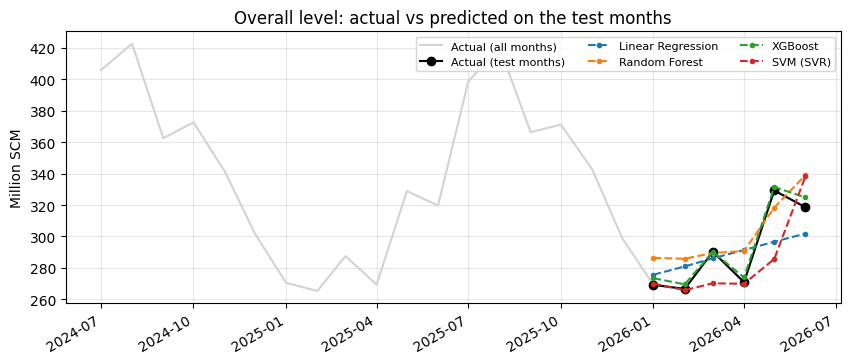

In [11]:
# 9.1 overall level: actual vs predicted for the 6 test months
train, test = time_split(monthly["overall"])

fig, ax = plt.subplots()
ax.plot(monthly["overall"]["DATE"], monthly["overall"][TARGET], color="lightgrey", label="Actual (all months)")
ax.plot(test["DATE"], test[TARGET], "ko-", label="Actual (test months)")
for name in ["Linear Regression", "Random Forest", "XGBoost", "SVM (SVR)"]:
    ax.plot(test["DATE"], test_predictions[("overall", name)], "--", marker=".", label=name)
ax.set_title("Overall level: actual vs predicted on the test months")
ax.set_ylabel("Million SCM")
ax.legend(ncol=3, fontsize=8)
fig.autofmt_xdate()
fig.savefig(FIGURES_DIR / "overall_test_predictions.png", dpi=130, bbox_inches="tight")
plt.show()

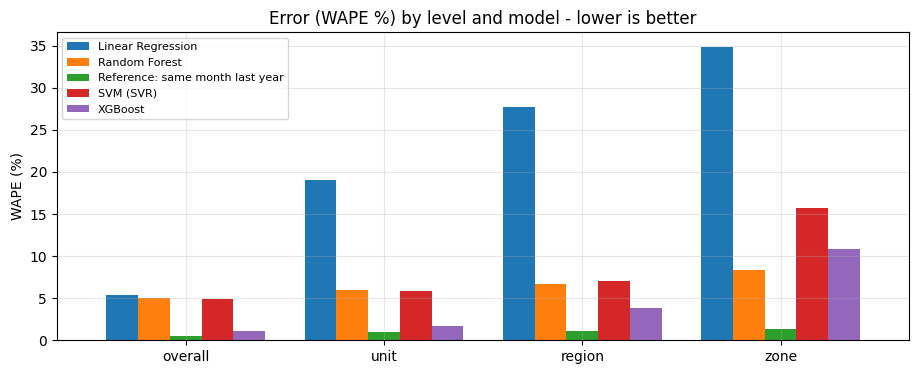

In [12]:
# 9.2 error (WAPE %) of every model at every level
wape = comparison.pivot(index="level", columns="model", values="WAPE_%").loc[list(LEVELS)]

ax = wape.plot(kind="bar", figsize=(11, 4), width=0.8)
ax.set_title("Error (WAPE %) by level and model - lower is better")
ax.set_ylabel("WAPE (%)")
ax.set_xlabel("")
ax.legend(fontsize=8)
plt.xticks(rotation=0)
plt.gcf().savefig(FIGURES_DIR / "model_comparison_wape.png", dpi=130, bbox_inches="tight")
plt.show()

## Step 10: Retrain on all 24 months and save the models

The test was only to *judge* the models. For the real forecast we want them to learn from **every** month we have, so we retrain them on all 24 months.

For each level we save one file containing all four trained models, the name of the best one, and the information the app needs to build features for next month.

In [13]:
for level, group_col in LEVELS.items():
    table = monthly[level]

    X_all = build_features(table, level)
    feature_columns = list(X_all.columns)

    # train all four models on the complete data
    fitted_models = {}
    for name, model in make_models(feature_columns).items():
        model.fit(X_all, table[TARGET])
        fitted_models[name] = model

    # everything the app needs, in one file
    bundle = {
        "level": level,
        "models": fitted_models,
        "best_model": best_models[level],
        "feature_columns": feature_columns,
        "groups": sorted(table[group_col].unique()) if group_col else [],
        "last_date": table["DATE"].max(),
        "start_date": START_DATE,
    }
    joblib.dump(bundle, MODELS_DIR / f"{level}_models.pkl", compress=3)   # compress=3 keeps the files small
    print(f"saved {level}_models.pkl   (best model: {best_models[level]})")

# also save the comparison table (the app shows it in the "Model performance" tab)
comparison.round(4).to_csv(REPORTS_DIR / "model_comparison.csv", index=False)
print("saved model_comparison.csv")

saved overall_models.pkl   (best model: XGBoost)


saved unit_models.pkl   (best model: XGBoost)


saved region_models.pkl   (best model: XGBoost)


saved zone_models.pkl   (best model: Random Forest)
saved model_comparison.csv


## Step 11: Predict next month

In [14]:
def predict_next_month(level, group=None, model_name=None):
    """Load a saved bundle and predict the month right after the last month of data."""
    bundle = joblib.load(MODELS_DIR / f"{level}_models.pkl")
    next_date = bundle["last_date"] + pd.DateOffset(months=1)

    # build ONE row with exactly the columns the model was trained on
    row = {col: 0.0 for col in bundle["feature_columns"]}
    row["month_num"] = next_date.month
    row["time_idx"] = (next_date.year - START_DATE.year) * 12 + (next_date.month - START_DATE.month) + 1
    if group is not None:
        row[f"{LEVELS[level]}_{group}"] = 1.0       # switch on the chosen unit / region / zone
    X_next = pd.DataFrame([row])[bundle["feature_columns"]]

    name = model_name or bundle["best_model"]
    value = max(float(bundle["models"][name].predict(X_next)[0]), 0.0)   # gas use cannot be negative
    return next_date, name, value

In [15]:
# 1) overall (billing month only)
next_date, model_name, value = predict_next_month("overall")
print(f"Forecast for {next_date:%B %Y}")
print(f"Overall ({model_name}): {value:.1f} million SCM")

Forecast for July 2026
Overall (XGBoost): 397.6 million SCM


In [16]:
# 2) by unit and by region
for level in ["unit", "region"]:
    bundle = joblib.load(MODELS_DIR / f"{level}_models.pkl")
    print(f"\n--- by {level} ({bundle['best_model']}) ---")
    for group in bundle["groups"]:
        _, _, v = predict_next_month(level, group)
        print(f"{group:28s} {v:8.2f} million SCM")


--- by unit (XGBoost) ---
Unit A - Karachi               309.09 million SCM
Unit B - Interior Sindh         69.77 million SCM


Unit Q-Baluchistan              17.02 million SCM



--- by region (XGBoost) ---


Hyderabad                       59.59 million SCM


Karachi Central                  8.54 million SCM


Karachi Eastern                245.24 million SCM


Karachi Western                 50.73 million SCM


Larkana                          3.27 million SCM
Mirpurkhas                       4.73 million SCM


Nawabshah                        0.50 million SCM


Quetta                          14.94 million SCM
Sukkur                           2.72 million SCM


In [17]:
# 3) the five zones with the largest forecast
zone_bundle = joblib.load(MODELS_DIR / "zone_models.pkl")
zone_forecast = pd.Series({g: predict_next_month("zone", g)[2] for g in zone_bundle["groups"]})
print(f"--- top 5 zones ({zone_bundle['best_model']}) ---")
print(zone_forecast.sort_values(ascending=False).head(5).round(2).to_string())

--- top 5 zones (Random Forest) ---
Bin Qasim        156.36
Kotri             57.42
Landhi            47.68
Hawksbay/SITE     40.39
Korangi-I         18.39


In [18]:
# Sanity check: the unit-level forecasts should add up to roughly the overall forecast
overall_value = predict_next_month("overall")[2]
unit_bundle = joblib.load(MODELS_DIR / "unit_models.pkl")
units_sum = sum(predict_next_month("unit", g)[2] for g in unit_bundle["groups"])
print(f"Overall forecast        : {overall_value:.1f}")
print(f"Sum of the unit forecasts: {units_sum:.1f}")

Overall forecast        : 397.6
Sum of the unit forecasts: 395.9


## Step 12: Conclusions and limitations

* We built **four forecasting versions** (overall, unit, region, zone) and compared **four models** on each. The best model per level was chosen on the 6 held-out months and then retrained on all 24 months.
* **Seasonality** (the month number) is the main thing the models learn.
* **The data is partly synthetic.** Year 2 is a noisy copy of year 1, so scores look better than they would on real data, and the simple reference ("same month last year") is very hard to beat. Do not present these scores as proof of real-world accuracy.
* **Only 24 months** (two examples of each calendar month) means the models cannot learn long-term trends, weather effects or business changes.
* **Zone level is the weakest**: most zones are small and noisy.
* We only used the inputs that were asked for (month, unit, region, zone).